# Ejercicios 3 y 4C: exploración adaptativa, parada y checkpoints

**Alcance (persona 3).** El ejercicio 3 pide que epsilon deje de depender del número de episodios y baje conforme el agente mejora. La idea 4C añade condiciones de parada basadas en el aprendizaje, guardado periódico de pesos y la posibilidad de recuperar un entrenamiento.

**Punto de partida.** Se usa el modelo final del ejercicio 2 sin cambiar nada más: DDQN, recompensa TWAP cuadrática, gamma 0,99, batch 64, buffer 2.000, dos capas de 32 neuronas, aprendizaje cada 16 pasos, copia a la red objetivo cada 128 pasos y 256 pasos de calentamiento. Activo REP, partición `train`. Lo único que cambia es **cómo se decide epsilon** y **cuándo y cómo termina el entrenamiento**, para que la comparación con el ejercicio 2 sea directa.

**Bloques modificados o nuevos**

| Archivo | Cambio |
|---|---|
| `src/agents/exploration.py` (nuevo) | Interfaz `ExplorationPolicy`, la agenda lineal anterior (`LinearDecayEpsilon`, como referencia) y la nueva `PerformanceEpsilon`. |
| `src/agents/dqn.py` (modificado) | `DDQNAgent` acepta `exploration_policy`. Si se inyecta, epsilon lo decide la política; sin ella el agente funciona como antes, así que los notebooks de los ejercicios 1 y 2 no cambian. |
| `src/training/evaluation.py` (nuevo) | Evaluación greedy de varios escenarios a la vez y puntuación de mejora. Incluye los 27 escenarios del ejercicio 2 y 9 de control distintos. |
| `src/training/trainer.py` (nuevo) | El bucle de entrenamiento, que estaba copiado en cada notebook, pasa a una clase `Trainer` con evaluación periódica, parada temprana, checkpoints `last`/`best` y `resume`. |
| `tests/test_exploration.py` (nuevo) | 20 tests: límites, ruido, independencia de los contadores, parada y reanudación idéntica. |

El enunciado plantea dos preguntas: **¿cómo determinamos que el algoritmo ha mejorado?** y **¿cómo trasladamos esa mejora a epsilon?** Las secciones 1 y 2 las responden; la 3 muestra el efecto y la 4 cubre la idea 4C.

In [1]:
import pickle, shutil, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from src.agents.dqn import DDQNAgent
from src.agents.exploration import LinearDecayEpsilon, PerformanceEpsilon
from src.environment.best_execution import BestExecutionEnv
from src.environment.config import EnvironmentConfig
from src.rewards import TwapRewardStrategy
from src.training.evaluation import usable_days, workshop_cases, probe_cases, TwapEvaluator
from src.training.trainer import Trainer, TrainerConfig, EarlyStopping, load_for_evaluation

root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'setup.py').exists())
with (root / 'data/rep_data.pkl').open('rb') as f:
    data = usable_days(pickle.load(f)['train'])
print('Días de REP train utilizados:', len(data))
CHECKPOINTS = root / 'tmp' / 'checkpoints_ex3'   # tmp/ está en .gitignore

Días de REP train utilizados: 58


## 1. ¿Cómo determinamos que el agente ha mejorado?

**Decisión: evaluar periódicamente la política greedy (sin exploración) en escenarios fijos.** Cada 2.000 pasos se para el entrenamiento y el agente ejecuta, con epsilon = 0, nueve órdenes CARE fijas.

Por qué no usamos la recompensa media de los episodios de entrenamiento, que es la opción más inmediata:

* **Está contaminada por la exploración.** Con epsilon alto, la recompensa refleja sobre todo acciones aleatorias, no lo que la red ha aprendido. Justo cuando hay que decidir si explorar menos, esa señal no informa de la política.
* **Depende del episodio.** Cada episodio tiene una duración (400-600 pasos) y un tamaño CARE distintos, y la penalización terminal cambia con ellos. Comparar episodios distintos añade ruido que no viene del aprendizaje.
* **Es la misma señal que optimiza el agente.** La evaluación mide directamente lo que pide el ejercicio 2: completar la orden siguiendo la pauta.

**Escenarios de control.** Son 9 órdenes, una por cada combinación de horizonte (400, 500 y 600 pasos) y tamaño CARE (7,5 %, 10 % y 12,5 %), en días y momentos distintos. **No comparten ninguna ventana con los 27 escenarios del ejercicio 2**, que reservamos para informar del resultado final. Así, la señal que mueve epsilon y la parada no se calcula sobre los mismos casos con los que se presenta el resultado. Todos están en `train`: el ejercicio no pide validación fuera de muestra.

**Puntuación de 0 a 1.** Para cada escenario:

* `tracking` vale 1 si el error medio frente a la pauta (MAE) iguala al del TWAP determinista, y 0 si lo supera en 0,05 o más (el margen que el ejercicio 2 fijó como objetivo); es lineal entre ambos.
* `complete` vale 1 si la orden CARE se completa.
* `puntuación = tracking × (0,5 + 0,5 × complete)`, y se promedia sobre los 9 escenarios.

La fórmula está pensada para que **las dos formas triviales de "cumplir" puntúen 0**: no comprar nunca no completa y no sigue la pauta; comprar en cada paso completa, pero en el primer 10 % del horizonte. Seguir la pauta sin rematar la orden vale como máximo 0,5. Solo una política que sigue la pauta **y** termina la orden llega a 1. La tabla siguiente lo comprueba con tres políticas de referencia.

In [2]:
probe = TwapEvaluator(probe_cases(data))       # señal durante el entrenamiento
workshop = TwapEvaluator(workshop_cases(data)) # informe final (27 escenarios del ejercicio 2)
overlap = {(c.day, c.start) for c in probe.cases} & {(c.day, c.start) for c in workshop.cases}
print('Ventanas compartidas entre control e informe:', len(overlap))
pd.DataFrame([{'día': c.day, 'inicio': c.start, 'horizonte': c.horizon, 'volumen CARE': c.volume}
              for c in probe.cases])

Ventanas compartidas entre control e informe: 0


,día,inicio,horizonte,volumen CARE
0,2018-01-22,875,400,30
1,2018-03-06,1964,400,40
2,2018-01-23,1420,400,50
3,2018-03-06,1894,500,37
4,2018-01-23,1370,500,50
5,2018-01-22,845,500,62
6,2018-01-23,1320,600,45
7,2018-01-22,815,600,60
8,2018-03-06,1824,600,75


Comprobación de la escala. La "pauta TWAP" de la tabla es la regla determinista escrita a partir del propio estado del agente (compra si la fracción ejecutada va por detrás de la fracción de tiempo transcurrida). Es lo que debería aprender el DDQN.

In [3]:
class ConstantPolicy:
    """Modelo Q ficticio que elige siempre la misma acción, para calibrar la puntuación."""
    def __init__(self, action): self.action = action
    def __call__(self, batch, training=False):
        q = np.zeros((len(batch), 2), dtype=np.float32); q[:, self.action] = 1
        return tf.constant(q)

class TwapAsQ:
    """La referencia TWAP expresada como modelo Q a partir del estado (tiempo y volumen restantes)."""
    def __call__(self, batch, training=False):
        time_left, vol_left = np.asarray(batch).T
        buy = (1 - vol_left) < (1 - time_left) - 1e-9   # va por detrás de la pauta -> compra
        return tf.constant(np.stack([~buy, buy], axis=1).astype(np.float32))

rows = {name: probe.evaluate(model) for name, model in
        [('nunca compra', ConstantPolicy(0)), ('compra en cada paso', ConstantPolicy(1)), ('pauta TWAP', TwapAsQ())]}
pd.DataFrame(rows).T[['score', 'completion', 'median_mae', 'tracking']].round(4)

,score,completion,median_mae,tracking
nunca compra,0.0,0.0,0.5010,0.0
compra en cada paso,0.0,1.0,0.4500,0.0
pauta TWAP,1.0,1.0,0.0074,1.0


## 2. ¿Cómo trasladamos la mejora a epsilon?

`PerformanceEpsilon` solo cambia epsilon al recibir una evaluación. **Los contadores de pasos y de episodios no lo modifican** (hay un test que lo comprueba con 10.000 llamadas). Hay dos vías por las que epsilon baja:

**Vía 1: mejora de resultados.** Sea `progreso` la mejor media móvil de las últimas 3 puntuaciones:

$$\varepsilon_{\text{resultados}} = \varepsilon_{\min} + (\varepsilon_{\max}-\varepsilon_{\min})\,(1-\text{progreso})$$

Si el agente greedy aún no hace nada útil (progreso 0), se explora al máximo; cuando reproduce la pauta y completa las órdenes (progreso 1), se explora el mínimo.

**Vía 2: exploración agotada ("conocer el espacio").** Si la media móvil no mejora en 4 evaluaciones seguidas (8.000 pasos, unos 16 episodios), interpretamos que explorar a ese nivel ya no aporta información nueva: el agente ya ha visto lo que podía descubrir así. Entonces el techo de exploración se multiplica por 0,7.

Esta segunda vía surgió de una primera prueba con solo la vía 1. La política llegó a seguir la pauta casi como el TWAP (MAE de unos 0,007), pero dejaba la última unidad sin ejecutar: puntuación de unos 0,5. Con la vía 1 sola, epsilon se quedaba fijo en 0,42 y el entrenamiento se estancaba. Con tanta exploración, los estados finales que visita la política greedy (vas casi en la pauta, queda una unidad) aparecen poco en el buffer y el agente no aprende a rematar. Reducir la exploración cuando ya no produce mejoras desbloquea esa fase.

$$\varepsilon = \max\big(\varepsilon_{\min},\ \min(\varepsilon_{\text{resultados}},\ \text{techo}_{\text{saturación}})\big)$$

**Protecciones frente al ruido**

| Parámetro | Valor | Motivo |
|---|---:|---|
| `epsilon_max` / `epsilon_min` | 1,0 / 0,05 | Los mismos límites que la agenda lineal del ejercicio 2, para comparar solo la forma de bajar. |
| `window` | 3 evaluaciones | Una evaluación aislada no decide sola. La puntuación salta porque `complete` es binario: a los 2.000 pasos una política casi aleatoria puntúa 0,27 por casualidad. Hasta tener 3 evaluaciones, epsilon no se mueve. |
| `min_delta` | 0,02 | Solo cuenta como mejora superar el mejor valor previo en más de este margen. |
| Trinquete | — | Epsilon nunca sube. Una mala evaluación tras una buena no devuelve exploración ya descartada. |
| `patience` / `stall_factor` | 4 / 0,7 | Vía 2: unos 16 episodios sin mejora antes de reducir el techo, y reducción gradual (0,7 → 0,49 → 0,34…). |
| `max_decrease` | 0,25 por evaluación | Una mejora brusca no hace caer epsilon de golpe. |

Fijamos estos valores antes de la comparación de la sección 3 y no se ajustaron con sus resultados. Solo `patience` y `stall_factor` se añadieron tras la prueba descrita arriba (semilla 11), que también forma parte de la comparación: eso lo tenemos en cuenta al interpretarla.

### Bucle de entrenamiento (`Trainer`)

El orden de cada interacción es el de los ejercicios 1 y 2:

`acción → step → experiencia al buffer → aprendizaje cada 16 pasos → copia a la red objetivo cada 128 → evento de paso a la política`

Cada 2.000 pasos se evalúa con los 9 escenarios de control. El resultado se pasa a la política de exploración, a la parada temprana y al checkpoint `best`. Las evaluaciones procesan los 9 escenarios a la vez, con una sola llamada a la red por paso, y no consumen la aleatoriedad del entrenamiento.

**Comprobación de equivalencia.** Con `LinearDecayEpsilon` y 50.000 pasos, el `Trainer` reproduce exactamente el modelo final del ejercicio 2: con la semilla 11 completa 27/27 órdenes con MAE mediano 0,011232, igual que el notebook de ese ejercicio. Por tanto, cualquier diferencia de la sección 3 se debe a epsilon y a la parada, no a la refactorización.

In [4]:
SEEDS = (11, 23, 42)
MODEL = dict(gamma=0.99, alpha=0.001, batch_size=64, buffer_size=2000, hidden_neurons=32)  # modelo final del ej. 2

def build(seed, policy):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(seed)
    env = BestExecutionEnv(data, EnvironmentConfig(seed=seed), TwapRewardStrategy(gamma=0.99, power=2))
    agent = DDQNAgent(env, epsilon=1.0, exploration_policy=policy, **MODEL)
    return env, agent

def run(kind, seed, checkpoint_dir=None):
    if kind == 'lineal':   # agenda del ejercicio 2: depende del contador de pasos
        env, agent = build(seed, LinearDecayEpsilon(1.0, 0.05, decay_steps=50_000))
        trainer = Trainer(agent, env, probe, TrainerConfig(max_steps=50_000, checkpoint_every=None))
    else:                  # ejercicio 3 + 4C
        env, agent = build(seed, PerformanceEpsilon())
        trainer = Trainer(agent, env, probe,
                          TrainerConfig(max_steps=100_000, checkpoint_every=10_000, checkpoint_dir=checkpoint_dir),
                          EarlyStopping())
    trainer.train()
    final = workshop.evaluate(agent.primary_model)
    return trainer, agent, final

## 3. Experimento: agenda lineal frente a epsilon adaptativo

Mismo modelo y mismas semillas (11, 23 y 42) que el ejercicio 2, con dos formas de explorar:

* **lineal**: la agenda del ejercicio 2, de 1 a 0,05 en 50.000 pasos, siempre 50.000 pasos;
* **adaptativo**: `PerformanceEpsilon` con parada temprana (sección 4) y un máximo de 100.000 pasos.

Las dos versiones se evalúan con los 9 escenarios de control cada 2.000 pasos, para poder dibujar sus curvas. El resultado final se informa en los **27 escenarios del ejercicio 2**, con el mismo criterio de "orden completa" y el mismo MAE. Tarda unos 25 minutos.

In [5]:
runs, summary = {}, []
for seed in SEEDS:
    for kind in ('lineal', 'adaptativo'):
        ckpt = CHECKPOINTS / f'{kind}_{seed}'
        shutil.rmtree(ckpt, ignore_errors=True)
        trainer, agent, final = run(kind, seed, ckpt if kind == 'adaptativo' else None)
        runs[(kind, seed)] = trainer
        summary.append({'epsilon': kind, 'semilla': seed, 'pasos': trainer.step,
                        'parada': trainer.stop_reason, 'mejor_eval_paso': trainer.best_step,
                        'segundos': round(trainer._elapsed),
                        'órdenes completas (27)': int(round(final['completion'] * 27)),
                        'MAE mediano': final['median_mae'], 'peor MAE': final['worst_mae']})
summary = pd.DataFrame(summary)
print('Referencia TWAP determinista, MAE mediano en los 27 escenarios:', round(float(np.median(workshop.reference_mae)), 4))
summary

Referencia TWAP determinista, MAE mediano en los 27 escenarios: 0.009


,epsilon,semilla,pasos,parada,mejor_eval_paso,segundos,órdenes completas (27),MAE mediano,peor MAE
0,lineal,11,50000,max_steps,40000,156,27,0.011232,0.012717
1,adaptativo,11,82000,target,82000,260,27,0.009137,0.011033
2,lineal,23,50000,max_steps,48000,157,27,0.015900,0.016246
3,adaptativo,23,34000,target,34000,103,27,0.010632,0.012796
4,lineal,42,50000,max_steps,20000,154,24,0.018512,0.021283
5,adaptativo,42,62000,target,62000,203,27,0.006208,0.010646


In [6]:
def first_target_step(evals, threshold=0.95):
    hit = evals[evals.score >= threshold]
    return int(hit.step.iloc[0]) if len(hit) else None

agg = summary.groupby('epsilon').agg(pasos_medios=('pasos', 'mean'), segundos_medios=('segundos', 'mean'),
                                     completas=('órdenes completas (27)', 'sum'),
                                     MAE_mediano=('MAE mediano', 'median'))
agg['completas'] = agg['completas'].astype(str) + ' / 81'
first = pd.DataFrame([{'epsilon': k, 'semilla': s, 'primera eval >= 0,95': first_target_step(t.eval_history)}
                      for (k, s), t in runs.items()])
display(agg)
first.pivot(index='semilla', columns='epsilon', values='primera eval >= 0,95')

,pasos_medios,segundos_medios,completas,MAE_mediano
epsilon,,,,
adaptativo,59333.333333,188.666667,81 / 81,0.009137
lineal,50000.000000,155.666667,78 / 81,0.015900


epsilon,adaptativo,lineal
semilla,,
11,70000.0,40000.0
23,32000.0,22000.0
42,48000.0,NaN


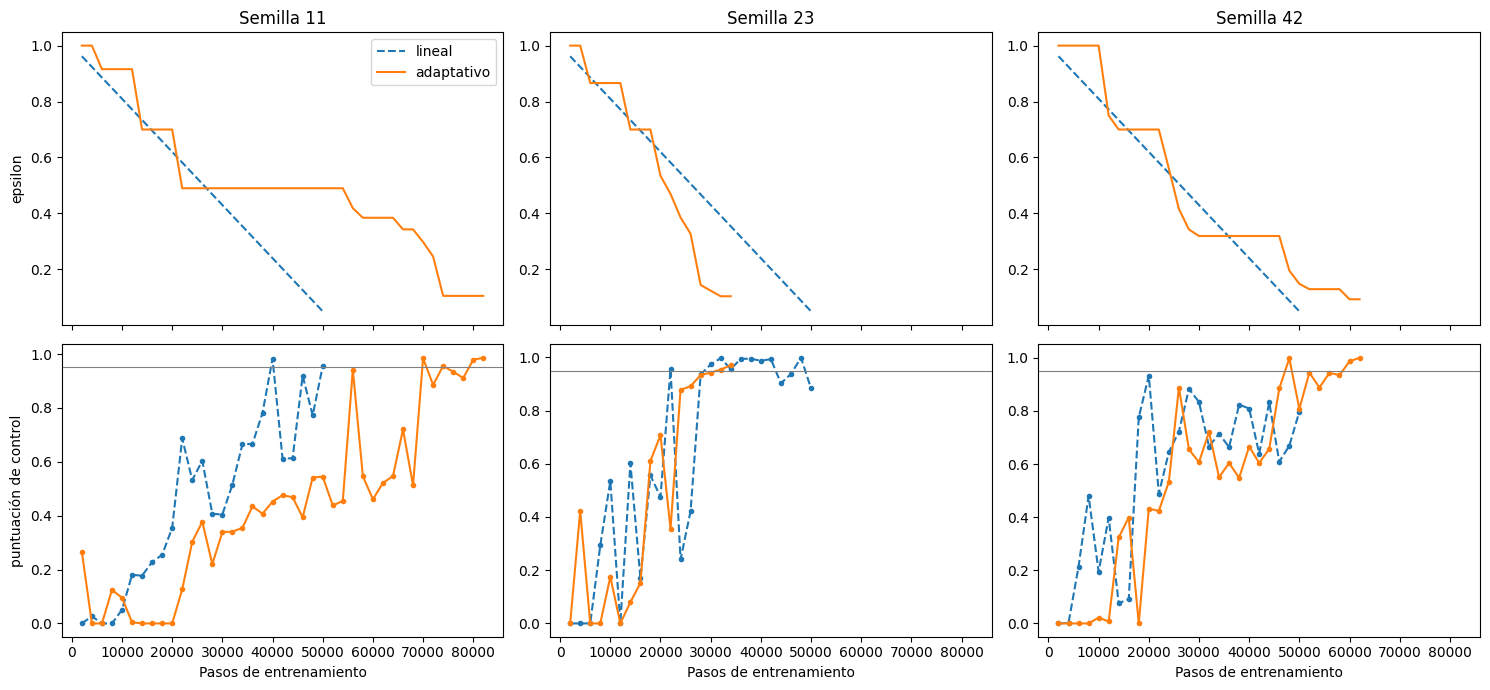

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharex=True)
for j, seed in enumerate(SEEDS):
    for kind, style in (('lineal', '--'), ('adaptativo', '-')):
        ev = runs[(kind, seed)].eval_history
        axes[0, j].plot(ev.step, ev.epsilon, style, label=kind)
        axes[1, j].plot(ev.step, ev.score, style, marker='.', label=kind)
    axes[0, j].set_title(f'Semilla {seed}')
    axes[1, j].axhline(0.95, color='grey', lw=0.8)
    axes[1, j].set_xlabel('Pasos de entrenamiento')
axes[0, 0].set_ylabel('epsilon'); axes[1, 0].set_ylabel('puntuación de control')
axes[0, 0].legend(); plt.tight_layout(); plt.show()

In [8]:
# Por qué baja epsilon en cada evaluación de la versión adaptativa (semilla 11)
ev = runs[('adaptativo', 11)].eval_history
ev['cambio'] = np.where(ev.epsilon < ev.epsilon_before - 1e-12, 'baja', '')
ev[['step', 'score', 'completion', 'median_mae', 'epsilon_before', 'epsilon', 'cambio']].round(4)

,step,score,completion,median_mae,epsilon_before,epsilon,cambio
0,2000,0.2658,1.0000,0.0463,1.0000,1.0000,
1,4000,0.0000,1.0000,0.4500,1.0000,1.0000,
2,6000,0.0000,0.0000,0.0721,1.0000,0.9158,baja
3,8000,0.1246,0.0000,0.0482,0.9158,0.9158,
4,10000,0.0953,0.0000,0.0509,0.9158,0.9158,
5,12000,0.0045,0.0000,0.0679,0.9158,0.9158,
6,14000,0.0000,0.0000,0.0935,0.9158,0.7000,baja
7,16000,0.0000,0.0000,0.1169,0.7000,0.7000,
8,18000,0.0000,0.0000,0.0872,0.7000,0.7000,
9,20000,0.0000,0.0000,0.0884,0.7000,0.7000,


### Interpretación

**Resultado final (27 escenarios del ejercicio 2, tres semillas)**

| | Lineal (ej. 2) | Adaptativo (ej. 3 + 4C) |
|---|---|---|
| Órdenes completas | 78 / 81 | **81 / 81** |
| MAE mediano por semilla (11 / 23 / 42) | 0,0112 / 0,0159 / 0,0185 | **0,0091 / 0,0106 / 0,0062** |
| Pasos de entrenamiento (11 / 23 / 42) | 50.000 / 50.000 / 50.000 | 82.000 / **34.000** / 62.000 |
| Motivo de parada | límite fijo | `target` en las tres |

Referencia: el TWAP determinista tiene un MAE mediano de 0,0090 en estos escenarios.

**Qué muestra el experimento**

1. **Epsilon sigue al aprendizaje y no al calendario.** Con la semilla 23, la política greedy completa las órdenes de control a los 18.000 pasos y epsilon pasa de 0,70 a 0,10 en los 14.000 pasos siguientes; el entrenamiento termina a los 34.000 pasos (un 32 % menos que la agenda lineal). Con la semilla 11, el agente tarda en rematar las órdenes; epsilon se queda en 0,49 mientras la puntuación no mejora y solo baja por la vía de saturación. Con una agenda fija las dos semillas habrían recibido exactamente la misma exploración.
2. **Las dos vías de bajada actúan.** La tabla de la semilla 11 muestra bajadas por mejora (pasos 6.000 y 56.000) y por estancamiento (0,92 → 0,70 → 0,49), que desbloquean la fase en la que el agente sigue la pauta pero no completa la orden.
3. **El epsilon adaptativo no aprende antes; es más prudente.** En las semillas 11 y 23 la agenda lineal alcanza antes una evaluación de control ≥ 0,95 (40.000 y 22.000 pasos, frente a 70.000 y 32.000), y con la semilla 42 no la alcanza. En esta tarea, bajar epsilon deprisa no perjudica tanto como cabría esperar. Nuestra política mantiene más exploración hasta tener evidencia sostenida de mejora. **No afirmamos que acelere el aprendizaje.**
4. **El resultado final es más consistente.** El adaptativo completa las 81 órdenes y su MAE mediano es menor en las tres semillas. Esa ventaja viene sobre todo de **cuándo termina** (idea 4C): solo para cuando la política de control alcanza el objetivo dos veces seguidas y se queda con los mejores pesos. Con la agenda lineal, el modelo entregado es el del paso 50.000, sea cual sea su estado: con la semilla 11 la evaluación de control oscila entre 0,61 y 0,98 en los últimos 10.000 pasos; con la semilla 42 la mejor evaluación fue a los 20.000 pasos y el modelo final deja 3 órdenes sin completar.
5. **Coste.** De media usa unos 59.000 pasos frente a 50.000 y algo más de tiempo, por las evaluaciones y por las semillas lentas. La duración la decide el aprendizaje: menos pasos cuando aprende pronto (semilla 23), más cuando no (semilla 11).

**Cautela.** Son tres semillas y la evaluación está dentro de `train`. La diferencia es consistente en las tres, pero no demuestra significación estadística ni generalización fuera de muestra. La semilla 11 se usó para diseñar la vía de saturación, así que la evidencia más limpia la dan las semillas 23 y 42. El resultado lineal de la semilla 42 (24/27) difiere del notebook del ejercicio 2 (27/27, mismo código y semilla); las semillas 11 y 23 coinciden exactamente. Lo atribuimos a diferencias numéricas entre plataformas (Linux x86 frente a macOS) en un entrenamiento largo de TensorFlow: en esta máquina el resultado es reproducible, como muestra la sección 4.

## 4. Idea 4C: parada según el aprendizaje, checkpoints y recuperación

**Condiciones de parada (`EarlyStopping`)**

| Condición | Regla | Motivo |
|---|---|---|
| `target` | Puntuación de control ≥ 0,95 en 2 evaluaciones seguidas | La política greedy ya completa las órdenes siguiendo la pauta; una sola evaluación podría ser casualidad. |
| `plateau` | La media móvil (3 evaluaciones) no mejora más de 0,01 en 15 evaluaciones (30.000 pasos) | No hay evidencia de progreso. Es más largo que la paciencia de epsilon (4) para que la vía 2 tenga tiempo de actuar antes de abandonar. |
| `max_steps` | 100.000 pasos | Límite de seguridad. |
| `min_steps` | No se para antes de 20.000 pasos | Con epsilon alto la política greedy aún no es representativa. |

Al terminar, el agente **recupera los pesos de su mejor evaluación** (`restore_best`), no los del último paso. Así una degradación final no se pierde por haber seguido entrenando.

**Checkpoints.** En `checkpoint_dir` se mantienen dos carpetas:

* `last`, cada 10.000 pasos y al terminar, para **continuar**: red principal con el estado del optimizador Adam, red objetivo, replay buffer, estados aleatorios de NumPy y del entorno, el episodio en curso, contadores, estado de epsilon y de la parada, e historial.
* `best`, cada vez que mejora la puntuación de control, para **evaluar o entregar** el mejor modelo.

In [9]:
ckpt = CHECKPOINTS / 'adaptativo_11'
for folder in ('last', 'best'):
    print(folder, sorted(p.name for p in (ckpt / folder).iterdir()))
import json
state = json.loads((ckpt / 'best' / 'state.json').read_text())
print('best guardado en el paso', state['step'], 'con puntuación', round(state['best_score'], 4))

last ['buffer.pkl', 'primary.keras', 'state.json', 'target.weights.h5']
best ['buffer.pkl', 'primary.keras', 'state.json', 'target.weights.h5']
best guardado en el paso 82000 con puntuación 0.9861


**Recuperar un entrenamiento.** Se interrumpe a los 30.000 pasos un entrenamiento idéntico al adaptativo de la semilla 11. Después se crea un agente nuevo con otra semilla, como en una sesión nueva, y se reanuda desde `last`. Si el checkpoint guarda todo lo necesario, el entrenamiento reanudado debe seguir el mismo camino que el ininterrumpido.

In [10]:
resume_dir = CHECKPOINTS / 'reanudar_11'
shutil.rmtree(resume_dir, ignore_errors=True)

# 1) Entrenamiento interrumpido a los 30.000 pasos (mismo modelo y semilla que 'adaptativo' 11)
env, agent = build(11, PerformanceEpsilon())
Trainer(agent, env, probe, TrainerConfig(max_steps=30_000, checkpoint_every=10_000,
                                         checkpoint_dir=resume_dir), EarlyStopping()).train()

# 2) "Nueva sesión": agente y entorno recién creados con otra semilla; todo se recupera del checkpoint
env, agent = build(1011, PerformanceEpsilon())
resumed = Trainer(agent, env, probe, TrainerConfig(max_steps=100_000, checkpoint_every=10_000,
                                                   checkpoint_dir=resume_dir), EarlyStopping())
resumed.resume(resume_dir / 'last')
print('Reanudado en el paso', resumed.step, 'con epsilon', round(resumed.agent.epsilon, 4))
resumed.train()

uninterrupted = runs[('adaptativo', 11)].eval_history.set_index('step')
continued = resumed.eval_history.set_index('step')
cols = ['score', 'epsilon']
comparison = uninterrupted[cols].join(continued[cols], lsuffix='_continuo', rsuffix='_reanudado', how='outer')
print('Parada:', resumed.stop_reason, 'en el paso', resumed.step,
      '| máxima diferencia de puntuación:', float((comparison.score_continuo - comparison.score_reanudado).abs().max()))
comparison.loc[20_000:].round(4)

Reanudado en el paso 30000 con epsilon 0.49


Parada: target en el paso 82000 | máxima diferencia de puntuación: 0.0


,score_continuo,epsilon_continuo,score_reanudado,epsilon_reanudado
step,,,,
20000,0.0000,0.7000,0.0000,0.7000
22000,0.1264,0.4900,0.1264,0.4900
24000,0.3032,0.4900,0.3032,0.4900
26000,0.3773,0.4900,0.3773,0.4900
28000,0.2202,0.4900,0.2202,0.4900
30000,0.3393,0.4900,0.3393,0.4900
32000,0.3404,0.4900,0.3404,0.4900
34000,0.3548,0.4900,0.3548,0.4900
36000,0.4345,0.4900,0.4345,0.4900


**Cargar el mejor modelo para evaluarlo.** `load_for_evaluation` carga `best` en un agente recién creado. Debe dar el mismo resultado en los 27 escenarios que el modelo con el que terminó el entrenamiento.

In [11]:
env, agent = build(11, PerformanceEpsilon())
load_for_evaluation(agent, CHECKPOINTS / 'adaptativo_11' / 'best')
pd.Series(workshop.evaluate(agent.primary_model)).round(4)

score         0.9861
completion    1.0000
median_mae    0.0091
worst_mae     0.0110
tracking      0.9861
dtype: float64

## 5. Decisiones y límites

**Decisiones principales**

* **Señal de mejora:** una evaluación greedy periódica en 9 escenarios de control, separados de los 27 de informe, en lugar de la recompensa de entrenamiento. Mide la política sin el ruido de la exploración ni el de la duración del episodio.
* **Puntuación:** combina completar la orden y seguir la pauta, de modo que las estrategias triviales (no comprar nunca, comprar en cada paso) puntúen 0.
* **Epsilon:** dos vías de bajada, por mejora de resultados y por exploración agotada, con media móvil, tolerancia, trinquete y paso máximo. No depende de pasos ni episodios.
* **Duración (4C):** parada por objetivo alcanzado o por meseta, con un mínimo y un máximo de pasos, recuperando los mejores pesos al terminar.
* **Checkpoints (4C):** `last` para continuar exactamente donde se dejó (pesos, optimizador, buffer, aleatoriedad y estado de epsilon) y `best` para evaluar. La reanudación reproduce el entrenamiento ininterrumpido.

**Límites**

* La evaluación cuesta tiempo: 9 episodios cada 2.000 pasos. Se reduce ejecutándolos en paralelo con una llamada a la red por paso.
* La puntuación depende del objetivo TWAP. Para otro objetivo (por ejemplo, batir el VWAP, idea 4A) habría que redefinir la señal, pero la política de exploración y el `Trainer` no cambian.
* Los umbrales (0,95, paciencia 4 y 15, factor 0,7) se fijaron con criterio y con una sola prueba previa; no son óptimos. Bajar la paciencia de epsilon acelera las semillas lentas a riesgo de explorar menos.
* Tres semillas, un activo (REP) y escenarios de `train`: el alcance que pide el enunciado, sin validación fuera de muestra.